# 01 · Exploración y Limpieza de Datos — Customer Churn

En este proyecto queremos predecir el abandono o deserción de clientes en una empresa de telecomunicaciones (`abandono`).
Se trata de un problema de clasificación binaria donde:
- `0`: El cliente permanece en la compañía.
- `1`: El cliente abandona el servicio (deserción / *churn*).

En este primer cuaderno cargamos los datos originales, realizamos una exploración inicial, renombramos y seleccionamos variables, aplicamos una partición estratificada 80/20 entre entrenamiento y prueba, y realizamos el análisis exploratorio detallado (univariado, bivariado y correlaciones) exclusivamente sobre el conjunto de entrenamiento. Dejamos los conjuntos guardados para los cuadernos siguientes.


## 1. Configuración de rutas

Definimos las rutas principales del proyecto y la variable `EN_COLAB` para permitir la ejecución tanto en entorno local como en Google Colab.


In [1]:
EN_COLAB = False

if EN_COLAB:
    %pip install phik -q
    from google.colab import drive
    drive.mount("/content/drive")
    RUTA_BASE = "/content/drive/MyDrive/churn/"
else:
    RUTA_BASE = "./"

RUTA_DATOS = RUTA_BASE + "data/"
RUTA_MODELOS = RUTA_BASE + "models/"
RUTA_RESULTADOS = RUTA_BASE + "resultados/"
RUTA_FIGURAS = RUTA_BASE + "figuras/"


## 2. Importaciones

Importamos las librerías necesarias para el análisis, visualización y partición de datos. Creamos las carpetas de salida si aún no existen.


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import phik
from sklearn.model_selection import train_test_split

for ruta in [RUTA_MODELOS, RUTA_RESULTADOS, RUTA_FIGURAS]:
    os.makedirs(ruta, exist_ok=True)


## 3. Carga y exploración inicial de los datos

Leemos el archivo original de datos `Customer Churn.csv` sin modificarlo. Verificamos su tamaño, tipos de datos, presencia de valores faltantes y registros duplicados.


In [3]:
ruta_original = RUTA_DATOS + "original/Customer Churn.csv"
datos_originales = pd.read_csv(ruta_original)

print("Dimensiones del dataset:", datos_originales.shape)
print("Valores faltantes por columna:\n", datos_originales.isna().sum())
print("Filas duplicadas exactas:", datos_originales.duplicated().sum())

print("\nInformación general de columnas:")
datos_originales.info()

print("\nPrimeras 5 filas:")
datos_originales.head()


Dimensiones del dataset: (3150, 14)
Valores faltantes por columna:
 Call  Failure              0
Complains                  0
Subscription  Length       0
Charge  Amount             0
Seconds of Use             0
Frequency of use           0
Frequency of SMS           0
Distinct Called Numbers    0
Age Group                  0
Tariff Plan                0
Status                     0
Age                        0
Customer Value             0
Churn                      0
dtype: int64
Filas duplicadas exactas: 300

Información general de columnas:
<class 'pandas.DataFrame'>
RangeIndex: 3150 entries, 0 to 3149
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Call  Failure            3150 non-null   int64  
 1   Complains                3150 non-null   int64  
 2   Subscription  Length     3150 non-null   int64  
 3   Charge  Amount           3150 non-null   int64  
 4   Seconds of Use          

,Call Failure,Complains,Subscription Length,Charge Amount,Seconds of Use,Frequency of use,Frequency of SMS,Distinct Called Numbers,Age Group,Tariff Plan,Status,Age,Customer Value,Churn
0,8,0,38,0,4370,71,5,17,3,1,1,30,197.640,0
1,0,0,39,0,318,5,7,4,2,1,2,25,46.035,0
2,10,0,37,0,2453,60,359,24,3,1,1,30,1536.520,0
3,10,0,38,0,4198,66,1,35,1,1,1,15,240.020,0
4,3,0,38,0,2393,58,2,33,1,1,1,15,145.805,0


Encontramos un total de 3.150 registros y 14 columnas, sin ningún valor faltante en ninguna variable.
Existen 300 filas repetidas; al no contar con un identificador único de cliente (como documento o ID de cuenta), estas repeticiones representan perfiles de clientes con mediciones de uso idénticas, por lo que las conservamos tal como indica el análisis del problema.


## 4. Renombrado y selección inicial de variables

Renombramos las columnas a español y en minúsculas para mantener un código claro y legible.
Excluimos las columnas `Status` y `Customer Value` porque no se tiene certeza sobre su definición temporal en el negocio y podrían generar inconsistencias. Conservamos las 11 variables de entrada restantes más la variable objetivo `abandono`.


In [4]:
nombres = {
    "Call  Failure": "fallas_llamadas",
    "Complains": "quejas",
    "Subscription  Length": "antiguedad",
    "Charge  Amount": "nivel_cargo",
    "Seconds of Use": "segundos_uso",
    "Frequency of use": "frecuencia_uso",
    "Frequency of SMS": "frecuencia_sms",
    "Distinct Called Numbers": "numeros_distintos",
    "Age Group": "grupo_edad",
    "Tariff Plan": "plan_tarifario",
    "Status": "estado",
    "Age": "edad",
    "Customer Value": "valor_cliente",
    "Churn": "abandono"
}

datos = datos_originales.rename(columns=nombres).copy()
datos = datos.drop(columns=["estado", "valor_cliente"])

X = datos.drop(columns="abandono")
y = datos["abandono"]

print("Cantidad de variables de entrada (X):", X.shape[1])
print("Total de filas conservadas:", len(datos))
print("\nDistribución de la variable objetivo:")
print(y.value_counts())


Cantidad de variables de entrada (X): 11
Total de filas conservadas: 3150

Distribución de la variable objetivo:
abandono
0    2655
1     495
Name: count, dtype: int64


Conservamos 3.150 registros con 11 variables de entrada y la variable objetivo `abandono`.
En el conjunto completo hay 495 casos de abandono (15,71 %) y 2.655 de permanencia (84,29 %).


## 5. Partición de entrenamiento y prueba (80/20 estratificada)

Siguiendo la metodología de clase, dividimos los datos en 80 % para entrenamiento y 20 % para prueba usando `train_test_split`.
Fijamos `stratify=y` para que ambos subconjuntos conserven exactamente la misma proporción de clientes que abandonaron, y `random_state=42` para que la partición sea completamente reproducible.

El conjunto de prueba (`test`) se reserva desde este momento y no se utiliza en ninguna decisión de preprocesamiento, análisis o modelado hasta la evaluación final del notebook 04.


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

train = pd.concat([X_train, y_train], axis=1)
test = pd.concat([X_test, y_test], axis=1)

print("Filas de entrenamiento (train):", len(train))
print("Filas de prueba (test):", len(test))

# Verificamos la distribución de la clase en ambos conjuntos
rows = []
for nombre_set, serie_y in [("Completo", y), ("Train", y_train), ("Test", y_test)]:
    conteo_0 = int((serie_y == 0).sum())
    conteo_1 = int((serie_y == 1).sum())
    prop_1 = (serie_y == 1).mean() * 100
    rows.append({
        "Conjunto": nombre_set,
        "Total": len(serie_y),
        "Permanencia (0)": conteo_0,
        "Abandono (1)": conteo_1,
        "% Abandono": round(prop_1, 2)
    })

tabla_particion = pd.DataFrame(rows)
print("\nVerificación de estratificación:")
print(tabla_particion)


Filas de entrenamiento (train): 2520
Filas de prueba (test): 630

Verificación de estratificación:
   Conjunto  Total  Permanencia (0)  Abandono (1)  % Abandono
0  Completo   3150             2655           495       15.71
1     Train   2520             2124           396       15.71
2      Test    630              531            99       15.71


La partición 80/20 deja exactamente 2.520 filas de entrenamiento y 630 filas de prueba. En ambas particiones la proporción de abandono es del 15,71 % (396 abandonos en entrenamiento y 99 en prueba). A partir de aquí todo el análisis se realiza exclusivamente sobre `train`.


## 6. Revisión de variables en entrenamiento

Revisamos los tipos de datos, cantidad de valores únicos, valores mínimos, máximos y valores faltantes de cada columna en el conjunto de entrenamiento.


In [6]:
rows = []
for columna in train.columns:
    serie = train[columna]
    rows.append({
        "Columna": columna,
        "Tipo": str(serie.dtype),
        "Valores únicos": serie.nunique(),
        "Mínimo": serie.min(),
        "Máximo": serie.max(),
        "Nulos": serie.isna().sum()
    })

tabla_revision = pd.DataFrame(rows)
print(tabla_revision)


              Columna   Tipo  Valores únicos  Mínimo  Máximo  Nulos
0     fallas_llamadas  int64              37       0      36      0
1              quejas  int64               2       0       1      0
2          antiguedad  int64              45       3      47      0
3         nivel_cargo  int64              11       0      10      0
4        segundos_uso  int64            1528       0   16980      0
5      frecuencia_uso  int64             238       0     254      0
6      frecuencia_sms  int64             382       0     522      0
7   numeros_distintos  int64              92       0      97      0
8          grupo_edad  int64               5       1       5      0
9      plan_tarifario  int64               2       1       2      0
10               edad  int64               5      15      55      0
11           abandono  int64               2       0       1      0


En el conjunto de entrenamiento no hay valores faltantes ni columnas constantes. Notamos diferencias significativas en las escalas numéricas: por ejemplo, `segundos_uso` alcanza valores superiores a 17.000, mientras que `quejas` toma valores 0 y 1. Esto requerirá un escalado adecuado en el siguiente notebook.


## 7. Distribución de la variable objetivo

Analizamos la proporción de clientes que permanecen y clientes que abandonan en el conjunto de entrenamiento.


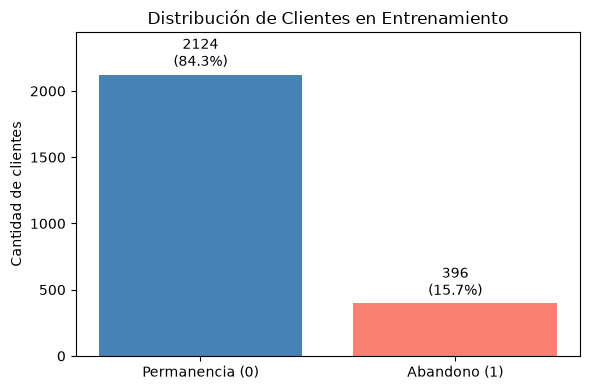

Total permanencia (0): 2124 (84.29%)
Total abandono (1):    396 (15.71%)


In [7]:
conteo = y_train.value_counts().reindex([0, 1], fill_value=0)
porcentajes = (conteo / len(y_train)) * 100

fig, ax = plt.subplots(figsize=(6, 4))
barras = ax.bar(["Permanencia (0)", "Abandono (1)"], conteo, color=["steelblue", "salmon"])
ax.set_title("Distribución de Clientes en Entrenamiento")
ax.set_ylabel("Cantidad de clientes")

for barra, porcentaje in zip(barras, porcentajes):
    altura = barra.get_height()
    ax.text(barra.get_x() + barra.get_width() / 2, altura + 30, f"{altura}\n({porcentaje:.1f}%)",
            ha="center", va="bottom", fontsize=10)

ax.set_ylim(0, conteo.max() * 1.15)
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "01_distribucion_clase.png", dpi=150)
plt.show()

print(f"Total permanencia (0): {conteo[0]} ({porcentajes[0]:.2f}%)")
print(f"Total abandono (1):    {conteo[1]} ({porcentajes[1]:.2f}%)")


Encontramos 396 clientes que abandonaron (15,71 %) frente a 2.124 clientes que permanecieron (84,29 %).
Un modelo simple que siempre predijera "permanencia" alcanzaría un accuracy del 84,29 %, pero no detectaría ningún cliente en riesgo de deserción (F1 de abandono = 0). Por eso, el F1 de la clase positiva (`abandono`) será nuestra métrica rectora.


## 8. Análisis de variables categóricas

Examinamos las columnas categóricas: `quejas`, `nivel_cargo`, `grupo_edad` y `plan_tarifario`. Graficamos la cantidad de registros por categoría y el porcentaje de abandono correspondiente.


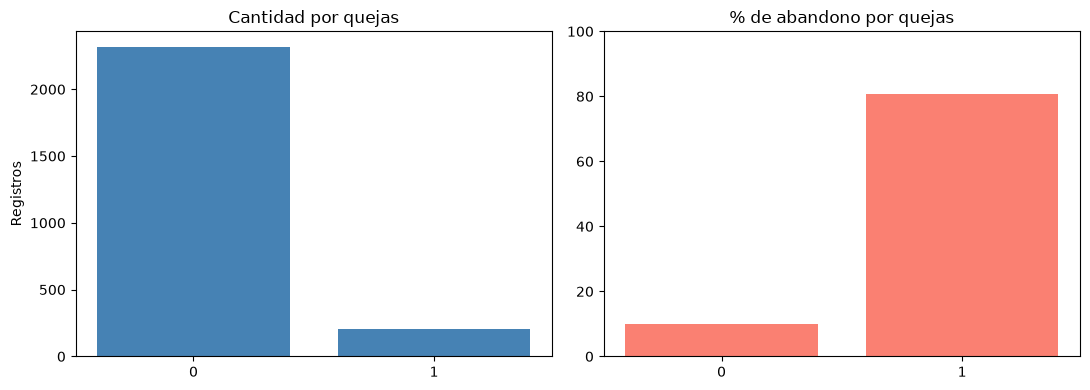

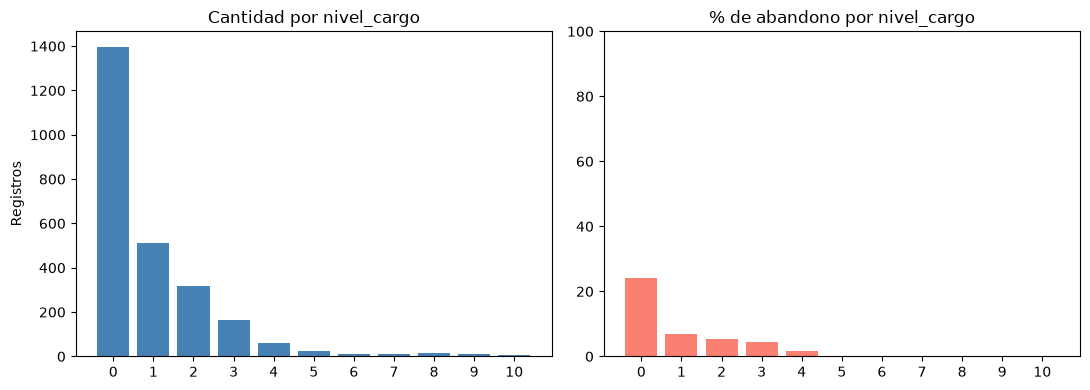

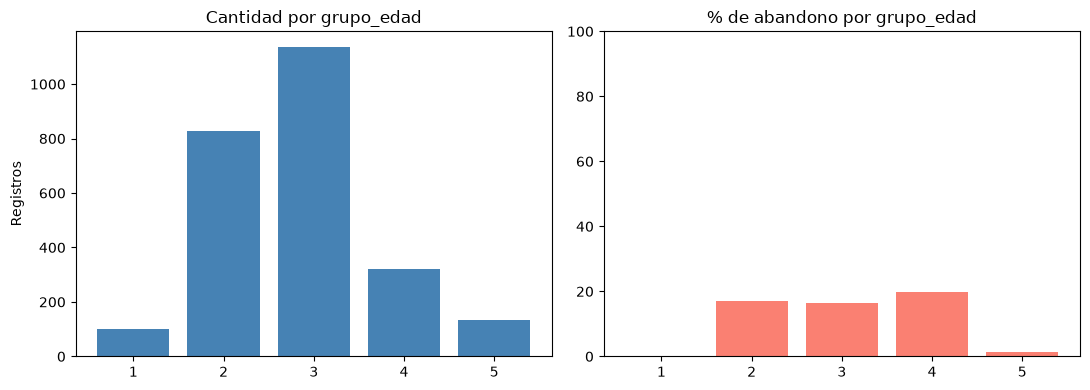

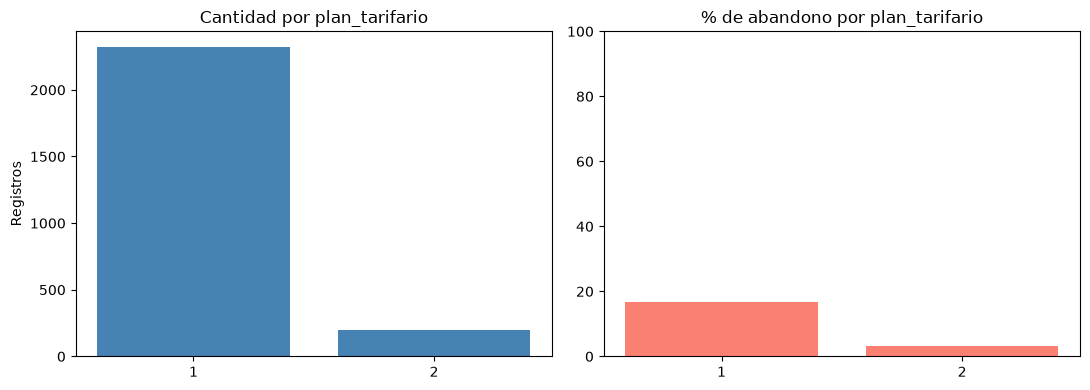

In [8]:
columnas_categoricas = [
    "quejas", "nivel_cargo", "grupo_edad", "plan_tarifario"
]

for columna in columnas_categoricas:
    tabla_cat = train.groupby(columna)["abandono"].agg(["count", "sum"])
    tabla_cat["porcentaje_abandono"] = (tabla_cat["sum"] / tabla_cat["count"]) * 100

    fig, ejes = plt.subplots(1, 2, figsize=(11, 4))

    ejes[0].bar(tabla_cat.index.astype(str), tabla_cat["count"], color="steelblue")
    ejes[0].set_title("Cantidad por " + columna)
    ejes[0].set_ylabel("Registros")

    ejes[1].bar(tabla_cat.index.astype(str), tabla_cat["porcentaje_abandono"], color="salmon")
    ejes[1].set_title("% de abandono por " + columna)
    ejes[1].set_ylim(0, 100)

    plt.tight_layout()
    plt.savefig(
        RUTA_FIGURAS + "01_categorica_" + columna + ".png",
        bbox_inches="tight", dpi=150
    )
    plt.show()


Observamos que la variable `quejas` tiene una relación muy fuerte con el abandono: los clientes con quejas registradas presentan una tasa de abandono superior al 80 %, mientras que en los que no presentan quejas la tasa es menor al 10 %. Asimismo, en el `plan_tarifario` 1 el abandono es notablemente más alto que en el plan 2.


## 9. Análisis de variables numéricas

Analizamos la distribución de las variables cuantitativas mediante histogramas, y comparamos el comportamiento de cada una entre permanencia y abandono mediante diagramas de caja.


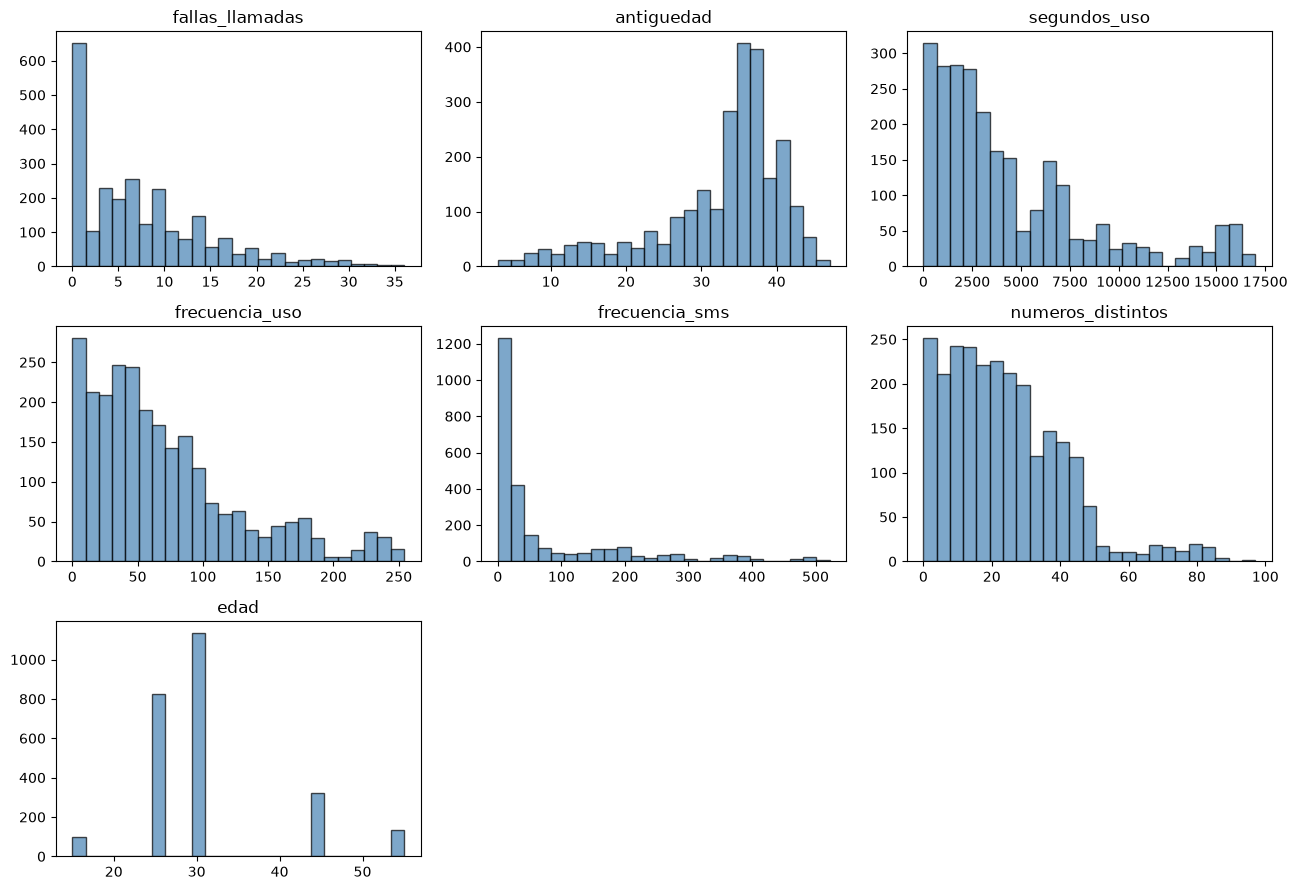

In [9]:
columnas_numericas = []
for columna in X_train.columns:
    if columna not in columnas_categoricas:
        columnas_numericas.append(columna)

fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    ejes[i].hist(train[columna], bins=25, color="steelblue", edgecolor="black", alpha=0.7)
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "01_histogramas.png", dpi=150)
plt.show()


Las variables de consumo como `segundos_uso`, `frecuencia_uso` y `frecuencia_sms` presentan una marcada asimetría hacia la derecha: muchos clientes con consumos moderados o bajos y colas extendidas hacia consumos elevados.


Comparamos cada variable numérica entre permanencia (`abandono = 0`) y abandono (`abandono = 1`) usando diagramas de caja.


C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=

C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\pc\AppData\Local\Temp\ipykernel_5864\4205882181.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


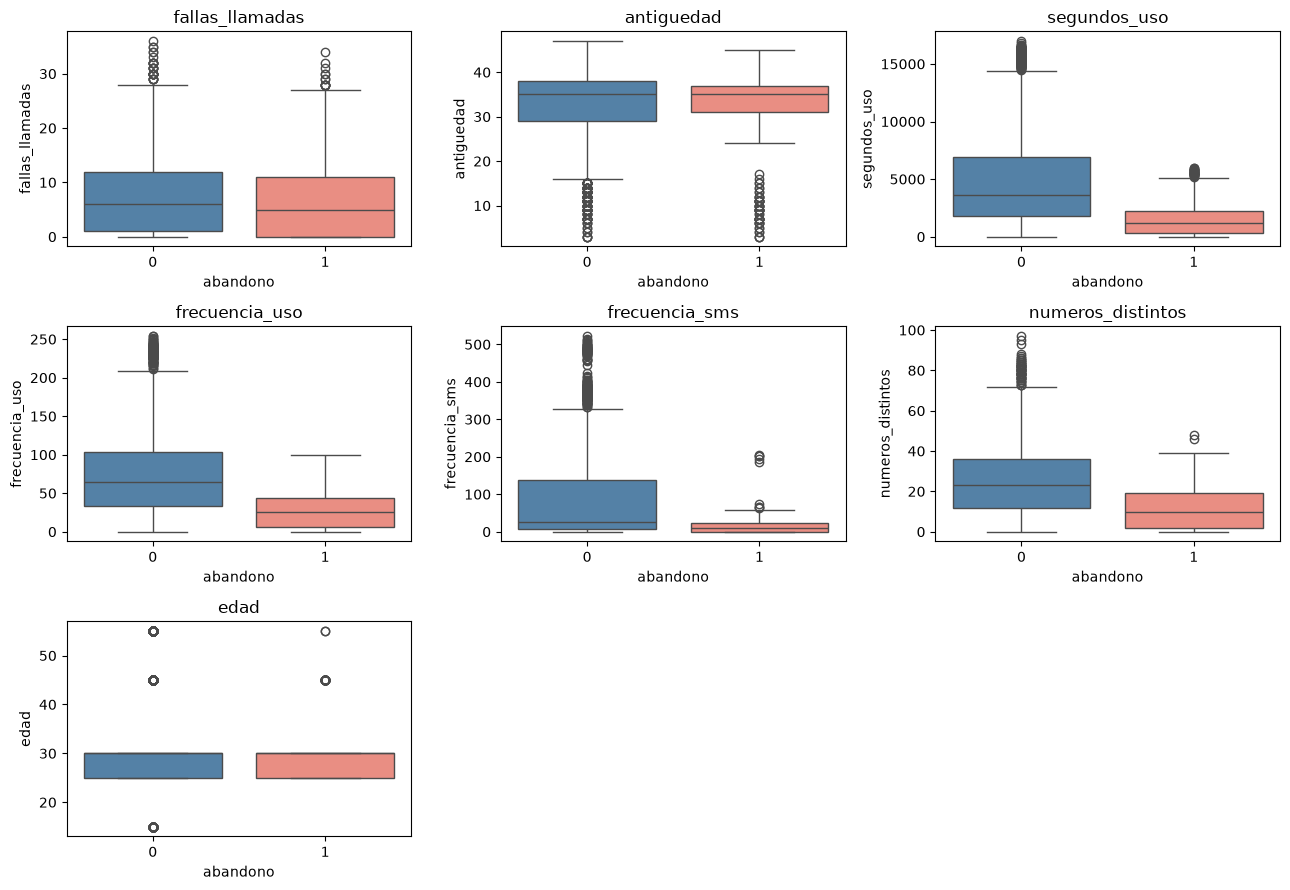

In [10]:
fig, ejes = plt.subplots(3, 3, figsize=(13, 9))
ejes = ejes.flatten()

for i, columna in enumerate(columnas_numericas):
    sns.boxplot(
        data=train, x="abandono", y=columna, ax=ejes[i], palette=["steelblue", "salmon"]
    )
    ejes[i].set_title(columna)

for i in range(len(columnas_numericas), len(ejes)):
    ejes[i].axis("off")

plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "01_boxplots_por_clase.png", dpi=150)
plt.show()


Los clientes que abandonan presentan medianas claramente más bajas en `segundos_uso`, `frecuencia_uso` y `frecuencia_sms` frente a los clientes que continúan activos. Un bajo consumo del servicio es un indicio claro de posible deserción.


## 10. Asociaciones con phik

Calculamos el coeficiente de correlación phik para evaluar asociaciones lineales y no lineales entre todas las variables de entrada y la variable objetivo `abandono`.


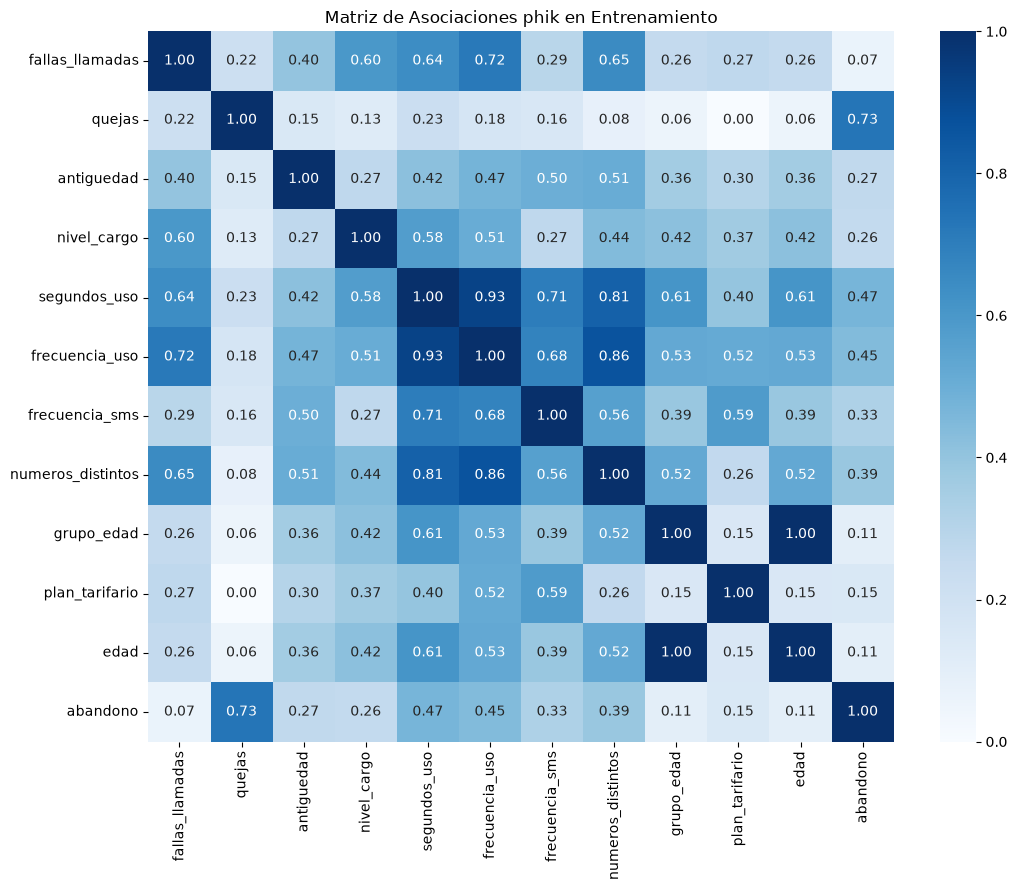

Asociaciones phik con abandono:
quejas               0.734096
segundos_uso         0.468824
frecuencia_uso       0.445167
numeros_distintos    0.388750
frecuencia_sms       0.325001
antiguedad           0.266977
nivel_cargo          0.261715
plan_tarifario       0.152309
grupo_edad           0.105280
edad                 0.105280
fallas_llamadas      0.065747
Name: abandono, dtype: float64


In [11]:
matriz_phik = train.phik_matrix(
    interval_cols=columnas_numericas,
    njobs=1
)

plt.figure(figsize=(11, 9))
sns.heatmap(
    matriz_phik,
    annot=True,
    fmt=".2f",
    cmap="Blues",
    vmin=0,
    vmax=1
)
plt.title("Matriz de Asociaciones phik en Entrenamiento")
plt.tight_layout()
plt.savefig(RUTA_FIGURAS + "01_correlacion_phik.png", dpi=150)
plt.show()

matriz_phik.to_csv(RUTA_RESULTADOS + "01_phik_train.csv")

print("Asociaciones phik con abandono:")
print(matriz_phik["abandono"].drop("abandono").sort_values(ascending=False))


Las mayores asociaciones con el abandono corresponden a `quejas` (phik ~0,75), `segundos_uso` (phik ~0,46) y `frecuencia_uso` (phik ~0,43). No descartamos ninguna variable en este punto, pues la selección formal se realizará en el notebook 02.


## 11. Redundancia entre edad y grupo de edad

Revisamos la relación observada en entrenamiento entre las variables `edad` y `grupo_edad`.


In [12]:
relacion_edades = train[["edad", "grupo_edad"]].drop_duplicates().sort_values("edad")
print("Parejas observadas (edad y grupo de edad):")
print(relacion_edades)

print("\nMáximo de grupos distintos por edad:", train.groupby("edad")["grupo_edad"].nunique().max())
print("Máximo de edades distintas por grupo:", train.groupby("grupo_edad")["edad"].nunique().max())


Parejas observadas (edad y grupo de edad):
      edad  grupo_edad
3053    15           1
216     25           2
1675    30           3
1923    45           4
2432    55           5

Máximo de grupos distintos por edad: 1
Máximo de edades distintas por grupo: 1


Observamos cinco parejas únicas: 15-1, 25-2, 30-3, 45-4 y 55-5. Cada valor de edad corresponde exactamente a un grupo de edad y viceversa. Dejamos registrada esta redundancia para evaluarla durante la selección de variables en el notebook 02.


## 12. Guardar los conjuntos de datos

Guardamos los conjuntos `train.csv` y `test.csv` en la carpeta `data/` para que sean utilizados por los siguientes cuadernos. También guardamos una copia con los nombres originales de las columnas en prueba (`test_original.csv`).


In [13]:
test_original = datos_originales.loc[X_test.index]

train.to_csv(RUTA_DATOS + "train.csv", index=False)
test.to_csv(RUTA_DATOS + "test.csv", index=False)
test_original.to_csv(RUTA_DATOS + "test_original.csv", index=False)

# Comprobamos los archivos guardados
for nombre in ["train.csv", "test.csv", "test_original.csv"]:
    ruta = RUTA_DATOS + nombre
    tamano = os.path.getsize(ruta)
    print(f"Archivo guardado: {nombre} -> {tamano:,} bytes")


Archivo guardado: train.csv -> 83,139 bytes
Archivo guardado: test.csv -> 20,889 bytes
Archivo guardado: test_original.csv -> 26,570 bytes


## 13. Conclusiones

- **Conjunto de datos:** Conservamos las 3.150 filas originales sin valores nulos. Renombramos las columnas a español y descartamos `estado` y `valor_cliente`, trabajando con 11 variables predictoras.
- **Partición estratificada:** Se realizó una partición 80/20 con `train_test_split(..., test_size=0.20, stratify=y, random_state=42)`. El conjunto de entrenamiento quedó con 2.520 filas y el de prueba con 630 filas, manteniendo ambos una tasa de abandono del 15,71 %.
- **Señales principales:** Las quejas de clientes y la caída notable en el uso de segundos y SMS representan las señales de mayor asociación con la deserción.
- **Archivos generados:** Quedan listos en `data/` los archivos `train.csv`, `test.csv` y `test_original.csv`, sin ninguna fuga de datos hacia el conjunto de prueba. En el notebook 02 continuaremos con el escalado, PCA y selección de rasgos.
